<a href="https://colab.research.google.com/github/WangariLM/CreditDefault/blob/main/creditdefaultanalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
url = "https://raw.githubusercontent.com/insaid2018/Term-2/master/Data/UCI_Credit_Card.csv"
df = pd.read_csv(url)

print(df.shape)
df.head()

(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   300

In [ ]:
df.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default.payment.next.month'],
      dtype='object')

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


In [ ]:

#Importing Libraries
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, roc_auc_score

from xgboost import XGBClassifier

In [ ]:
#Droping ID column coz we wouldn't want row ordering to influence the model
df = df.drop(columns=["ID"])
#Selecting Categorical Features
# These are categorical but stored as integers → convert to category
cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]

df[cat_cols] = df[cat_cols].astype("category")

In [ ]:
#Define X and y and Split the data into train and test set
target_col = "default.payment.next.month"

# Separate features and target
X = df.drop(columns=[target_col])
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Custom Feature Engineering Transformer

In [ ]:

class CreditFeatureEngineer(BaseEstimator, TransformerMixin):
    """
    Creates financial behavior features:
    - Credit utilization
    - Repayment strength
    - Payment delay behavior
    - Stability (volatility)
    """

    def fit(self, X, y=None):
        # No learning needed (stateless transformer)
        return self

    def transform(self, X):
        X = X.copy()

        # -------------------------------
        # Identify column groups
        # -------------------------------
        bill_cols = [c for c in X.columns if "BILL_AMT" in c]
        pay_cols = [c for c in X.columns if "PAY_AMT" in c]

        # Payment delay history (exclude PAY_AMT columns)
        pay_status_cols = [c for c in X.columns if "PAY_" in c and c not in pay_cols]

        # -------------------------------
        # 1. CREDIT UTILIZATION
        # -------------------------------
        X["UTIL_MEAN"] = X[bill_cols].mean(axis=1) / (X["LIMIT_BAL"] + 1e-6)
        X["UTIL_MAX"] = X[bill_cols].max(axis=1) / (X["LIMIT_BAL"] + 1e-6)

        # -------------------------------
        # 2. REPAYMENT STRENGTH
        # -------------------------------
        X["PAY_SUM"] = X[pay_cols].sum(axis=1)
        X["BILL_SUM"] = X[bill_cols].sum(axis=1)
        X["REPAY_RATIO"] = X["PAY_SUM"] / (X["BILL_SUM"] + 1e-6)

        # -------------------------------
        # 3. PAYMENT DELAY BEHAVIOR
        # -------------------------------
        X["DELAY_MAX"] = X[pay_status_cols].max(axis=1)
        X["DELAY_MEAN"] = X[pay_status_cols].mean(axis=1)

        # Trend: worsening or improving delay behavior
        X["DELAY_TREND"] = (
            X[pay_status_cols].iloc[:, -1] - X[pay_status_cols].iloc[:, 0]
        )

        # -------------------------------
        # 4. STABILITY FEATURES
        # -------------------------------
        X["PAY_STD"] = X[pay_cols].std(axis=1)
        X["BILL_STD"] = X[bill_cols].std(axis=1)

        return X

Preprocessing Pipeline

In [ ]:

# Dynamic numeric selector:
# - Automatically includes engineered features
# - Excludes categorical columns because they are now dtype "category"
numeric_selector = make_column_selector(dtype_include=np.number)

# Numeric preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_selector),
        ("cat", categorical_transformer, cat_cols)
    ],
    remainder="drop"
)

Defining XGBoost Classifier

In [ ]:

model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

In [ ]:
#Full Pipeline
clf = Pipeline(steps=[
    ("feature_engineering", CreditFeatureEngineer()),  # create behavioral features
    ("preprocessing", preprocessor),                  # clean + encode
    ("model", model)                                  # train model
])

#Train Model
clf.fit(X_train, y_train)

Pipeline(steps=[('feature_engineering', CreditFeatureEngineer()),
                ('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7c0e1851f530>),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['SEX', 'E...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=None,
                               num_parallel_tree=None, ...))])

Model Evaluation

In [ ]:

y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:, 1]

print("====================================")
print("MODEL PERFORMANCE")
print("====================================\n")

print("AUC SCORE:", roc_auc_score(y_test, y_proba))
print("\nCLASSIFICATION REPORT:\n")
print(classification_report(y_test, y_pred))

MODEL PERFORMANCE

AUC SCORE: 0.7827731693444567

CLASSIFICATION REPORT:

              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.66      0.36      0.47      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.66      0.68      6000
weighted avg       0.80      0.82      0.80      6000



Feature Importance

In [ ]:
#Step 1: Extract feature names from pipeline
# Get trained pipeline components
preprocessor = clf.named_steps["preprocessing"]
model = clf.named_steps["model"]

In [ ]:
#Get Numeric features come from:
#a. Original numeric columns
#b. Engineered features
numeric_features = preprocessor.transformers_[0][2]

#Get Categorical Feature Names
cat_encoder = preprocessor.transformers_[1][1].named_steps["encoder"]

cat_features = cat_encoder.get_feature_names_out(cat_cols)

#Combine all Feature Names
import numpy as np

feature_names = np.concatenate([numeric_features, cat_features])

In [ ]:
#Get Feature Importance from Model
import pandas as pd

importance = model.feature_importances_

feat_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importance
})

feat_importance_df = feat_importance_df.sort_values(
    by="importance",
    ascending=False
)

In [ ]:
#View  Features Importance
#print(feat_importance_df.head(15))
print(feat_importance_df)

        feature  importance
25    DELAY_MAX    0.317108
2         PAY_0    0.238360
26   DELAY_MEAN    0.033290
23     BILL_SUM    0.021028
3         PAY_2    0.020038
27  DELAY_TREND    0.016355
21     UTIL_MAX    0.015533
22      PAY_SUM    0.014243
0     LIMIT_BAL    0.013990
29     BILL_STD    0.013257
24  REPAY_RATIO    0.012517
4         PAY_3    0.012184
16     PAY_AMT3    0.011533
15     PAY_AMT2    0.011376
20    UTIL_MEAN    0.010963
7         PAY_6    0.010867
9     BILL_AMT2    0.010772
8     BILL_AMT1    0.010703
37  EDUCATION_5    0.010684
14     PAY_AMT1    0.010495
6         PAY_5    0.010491
19     PAY_AMT6    0.010129
34  EDUCATION_2    0.009754
5         PAY_4    0.009584
41   MARRIAGE_2    0.009567
40   MARRIAGE_1    0.009326
12    BILL_AMT5    0.009126
28      PAY_STD    0.009120
17     PAY_AMT4    0.009002
13    BILL_AMT6    0.008956
30        SEX_1    0.008697
11    BILL_AMT4    0.008569
18     PAY_AMT5    0.008538
1           AGE    0.008336
10    BILL_AMT3    0

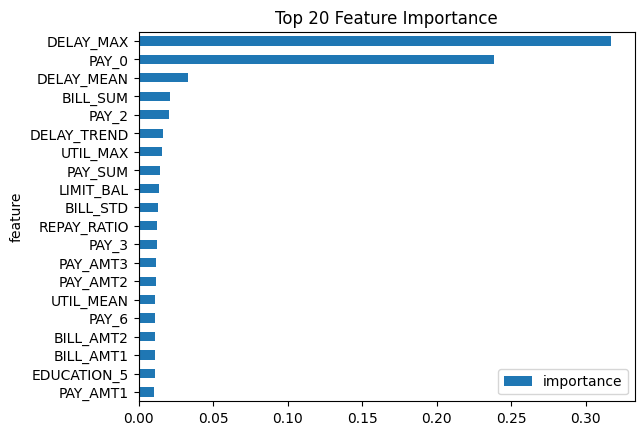

In [ ]:
#Feature Importance Visualization
import matplotlib.pyplot as plt

feat_importance_df.head(20).plot(
    kind="barh",
    x="feature",
    y="importance"
)

plt.gca().invert_yaxis()
plt.title("Top 20 Feature Importance")
plt.show()

SHAP Analysis

In [ ]:
import shap
#Extract Feature from Pipeline
# Extract trained components
feature_engineer = clf.named_steps["feature_engineering"]
preprocessor = clf.named_steps["preprocessing"]
model = clf.named_steps["model"]

In [ ]:
#Transform the data Manually
#We must pass data exactly how the model sees it.
# Apply feature engineering
X_train_fe = feature_engineer.transform(X_train)

# Apply preprocessing (encoding, imputation)
X_train_processed = preprocessor.transform(X_train_fe)

In [ ]:
#Get Feature Names
# Numeric features (after FE)
numeric_features = preprocessor.transformers_[0][2]

# Categorical features (after encoding)
cat_encoder = preprocessor.transformers_[1][1].named_steps["encoder"]
cat_features = cat_encoder.get_feature_names_out(cat_cols)

# Combine
import numpy as np
feature_names = np.concatenate([numeric_features, cat_features])

In [ ]:
#Create Shap Explainer, since its XGBoost so we go with tree explainer
explainer = shap.TreeExplainer(model)

#Calculate SHAP values
shap_values = explainer.shap_values(X_train_processed)

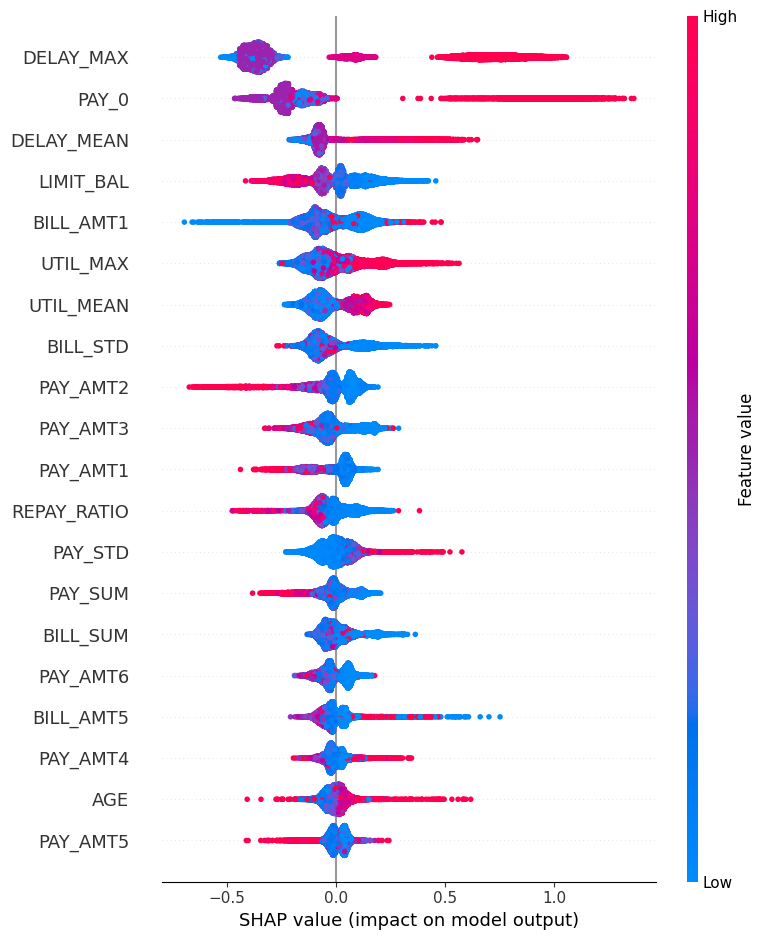

In [ ]:
#Global Shap Summary (Most Important)
shap.summary_plot(shap_values, X_train_processed, feature_names=feature_names)

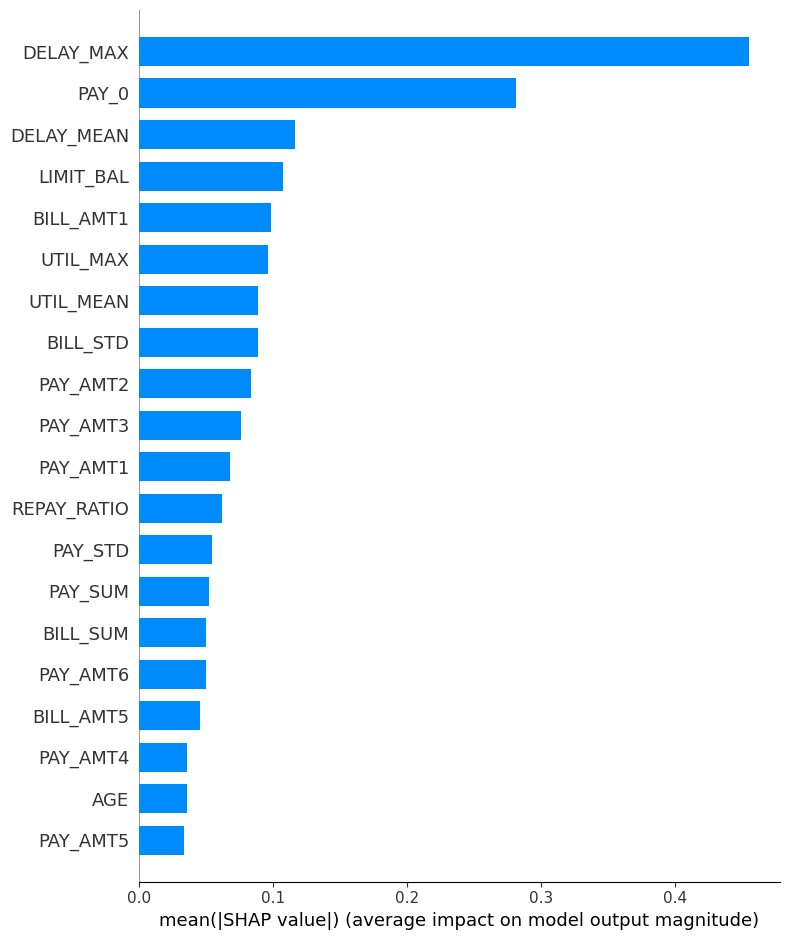

In [ ]:
#Bar Version of the summary
shap.summary_plot(shap_values, X_train_processed, feature_names=feature_names, plot_type="bar")